# R-KalWeNN no House Prices

Notebook limpo, escrito para ser lido. Nada de índice compacto, nada de média em
forma de matriz: a memória é um dicionário por RAM node, a atualização é exemplo
a exemplo na ordem de apresentação, e cada média é uma função que recebe a lista
de pares do exemplo e devolve um número.

É mais lento que o notebook 07, de propósito. Cada trecho pode ser lido e
conferido à mão.

## Roteiro

- **Seção 0** dados e pré-processamento, iguais aos do código da tese.
- **Seção 1** codificação: termômetro, mapeamento e endereços.
- **Seção 2** os dois modelos, ReW e R-KalWeNN, cada um em uma célula.
- **Seção 3** as médias de agregação das duas famílias.
- **Seção 4** conferências à mão, para o resto do notebook ter chão.
- **Seção 5** erro por agregação, com termômetro e tupla fixos.
- **Seção 6** estabilidade entre execuções.
- **Seção 7** termômetro contra tupla, e a escolha do ponto de operação.
- **Seção 8** os seis hiperparâmetros do filtro.

---
## 0. Dados

Mesmas células do notebook 06, que reproduzem o pré-processamento do `houseprice.py` da tese.

In [8]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew, boxcox_normmax
from scipy.special import boxcox1p
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

# paleta do artigo
C_REW, C_KAL, C_TRES, C_EIXO, C_TIT = "#db3763", "#16c1d4", "#5c7f44", "#9c7b8e", "#2b2a5e"

BASE_DADOS   = "https://raw.githubusercontent.com/ankita1112/House-Prices-Advanced-Regression/master/"
TEST_SIZE    = 0.33          # houseprice.py
RANDOM_STATE = 0             # houseprice.py
REF_TESE     = 0.278         # MAE da ReW publicado, escala log1p

print("pronto")

pronto


In [9]:
train = pd.read_csv(BASE_DADOS + "train.csv")
test  = pd.read_csv(BASE_DADOS + "test.csv")

train = train[train.GrLivArea < 4500]                  # linha 73 do original
train.reset_index(drop=True, inplace=True)
train["SalePrice"] = np.log1p(train["SalePrice"])      # linha 82: alvo em log1p

train.drop(columns=["Id"], axis=1, inplace=True)
test.drop(columns=["Id"], axis=1, inplace=True)
y = train["SalePrice"].reset_index(drop=True)

all_data = pd.concat((train, test)).reset_index(drop=True)   # linha 106
all_data.drop(["SalePrice"], axis=1, inplace=True)

print(f"train.csv: {train.shape}   test.csv: {test.shape}")
print(f"alvo em log1p: {y.min():.4f} a {y.max():.4f}   média {y.mean():.4f}   desvio {y.std():.4f}")
print(f"  em dólares: ${np.expm1(y.min()):,.0f} a ${np.expm1(y.max()):,.0f}")
print(f"all_data: {all_data.shape}")

train.csv: (1458, 80)   test.csv: (1459, 79)
alvo em log1p: 10.4603 a 13.5345   média 12.0240   desvio 0.3997
  em dólares: $34,900 a $755,000
all_data: (2917, 79)


In [10]:
for c in ["Alley", "PoolQC", "MiscFeature", "Fence", "FireplaceQu", "GarageType",
          "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond",
          "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]:
    all_data[c] = all_data[c].fillna("None")

for c in ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
          "BsmtHalfBath", "GarageYrBlt", "GarageArea", "GarageCars", "MasVnrArea"]:
    all_data[c] = all_data[c].fillna(0)

all_data["LotFrontage"] = all_data.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.mean()))

all_data["MSSubClass"] = all_data["MSSubClass"].astype(str)   # códigos, não quantidades
all_data["MSZoning"] = all_data.groupby("MSSubClass")["MSZoning"].transform(
    lambda x: x.fillna(x.mode()[0]))
all_data["YrSold"] = all_data["YrSold"].astype(str)
all_data["MoSold"] = all_data["MoSold"].astype(str)

all_data["Functional"]  = all_data["Functional"].fillna("Typ")
all_data["Utilities"]   = all_data["Utilities"].fillna("AllPub")
all_data["Exterior1st"] = all_data["Exterior1st"].fillna(all_data["Exterior1st"].mode()[0])
all_data["Exterior2nd"] = all_data["Exterior2nd"].fillna(all_data["Exterior2nd"].mode()[0])
all_data["KitchenQual"] = all_data["KitchenQual"].fillna("TA")
all_data["SaleType"]    = all_data["SaleType"].fillna(all_data["SaleType"].mode()[0])
all_data["Electrical"]  = all_data["Electrical"].fillna("SBrkr")

print(f"colunas com NaN restante: {(all_data.isna().sum() > 0).sum()}")

colunas com NaN restante: 0


In [11]:
def fixing_skewness(df):
    puladas = []
    numeric = df.dtypes[df.dtypes != "object"].index
    skewed = df[numeric].apply(lambda x: skew(x)).sort_values(ascending=False)
    alvo = skewed[abs(skewed) > 0.5].index
    for feat in alvo:
        try:
            df[feat] = boxcox1p(df[feat], boxcox_normmax(df[feat] + 1))
        except Exception:
            puladas.append(feat)
    return len(alvo), puladas


n_alvo, puladas = fixing_skewness(all_data)
print(f"boxcox aplicado em {n_alvo - len(puladas)} de {n_alvo} colunas assimétricas")
if puladas:
    print(f"  sem transformar (BracketError do scipy): {puladas}")

all_data = all_data.drop(["Utilities", "Street", "PoolQC"], axis=1)

all_data["TotalSF"]       = all_data["TotalBsmtSF"] + all_data["1stFlrSF"] + all_data["2ndFlrSF"]
all_data["YrBltAndRemod"] = all_data["YearBuilt"] + all_data["YearRemodAdd"]
all_data["Total_sqr_footage"] = (all_data["BsmtFinSF1"] + all_data["BsmtFinSF2"] +
                                 all_data["1stFlrSF"] + all_data["2ndFlrSF"])
all_data["Total_Bathrooms"]   = (all_data["FullBath"] + 0.5 * all_data["HalfBath"] +
                                 all_data["BsmtFullBath"] + 0.5 * all_data["BsmtHalfBath"])
all_data["Total_porch_sf"]    = (all_data["OpenPorchSF"] + all_data["3SsnPorch"] +
                                 all_data["EnclosedPorch"] + all_data["ScreenPorch"] +
                                 all_data["WoodDeckSF"])

all_data["haspool"]      = (all_data["PoolArea"]    > 0).astype(int)
all_data["has2ndfloor"]  = (all_data["2ndFlrSF"]    > 0).astype(int)
all_data["hasgarage"]    = (all_data["GarageArea"]  > 0).astype(int)
all_data["hasbsmt"]      = (all_data["TotalBsmtSF"] > 0).astype(int)
all_data["hasfireplace"] = (all_data["Fireplaces"]  > 0).astype(int)

final_features = pd.get_dummies(all_data).reset_index(drop=True)
print(f"depois do one-hot: {final_features.shape}")

/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)
/Users/helenaburock/Git/estudos_ml/.venv/lib/python3.9/site-packages/scipy/stats/_morestats.py:1298: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r, prob = _stats_py.pearsonr(xvals, yvals)


boxcox aplicado em 25 de 27 colunas assimétricas
  sem transformar (BracketError do scipy): ['LotArea', '1stFlrSF']
depois do one-hot: (2917, 333)


In [12]:
X = final_features.iloc[:len(y), :]

outliers = [30, 88, 462, 631, 1322]
X  = X.drop(X.index[outliers])
y_ = y.drop(y.index[outliers])

def overfit_reducer(df):
    return [c for c in df.columns
            if df[c].value_counts().iloc[0] / len(df) * 100 > 99.94]

descartadas = overfit_reducer(X)
X = X.drop(descartadas, axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_, test_size=TEST_SIZE, random_state=RANDOM_STATE)
X_train, X_test = X_train.values.astype(float), X_test.values.astype(float)
y_train, y_test = y_train.values, y_test.values
N_TREINO, N_ATRIB = len(X_train), X_train.shape[1]

print(f"overfit_reducer descartou {len(descartadas)} colunas -> {X.shape}")
print(f"treino {N_TREINO}   teste {len(X_test)}   atributos {N_ATRIB}")
print(f"a tese reporta:  treino 973   teste 480")
print(f"alvo (log1p): treino {y_train.min():.3f} a {y_train.max():.3f}")

overfit_reducer descartou 1 colunas -> (1453, 332)
treino 973   teste 480   atributos 332
a tese reporta:  treino 973   teste 480
alvo (log1p): treino 10.460 a 13.534


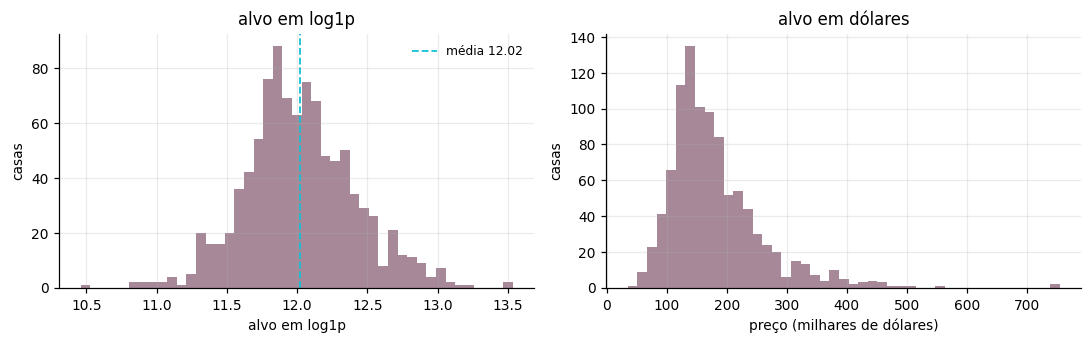

REFERÊNCIAS (escala log1p)

  chutar a média do treino   : MAE 0.3151
  chutar a mediana do treino : MAE 0.3156

  ReW publicada (Neurocomputing 416, Tabela 2): MAE 0.278

  variância do alvo no treino: 0.1537   desvio 0.3920
  0.278 em log1p equivale a 32.0% de erro relativo


In [13]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(y_train, bins=45, color=C_EIXO, alpha=.9)
ax[0].axvline(y_train.mean(), color=C_KAL, ls="--", lw=1.2, label=f"média {y_train.mean():.2f}")
ax[0].set(xlabel="alvo em log1p", ylabel="casas", title="alvo em log1p")
ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(np.expm1(y_train) / 1e3, bins=45, color=C_EIXO, alpha=.9)
ax[1].set(xlabel="preço (milhares de dólares)", ylabel="casas", title="alvo em dólares")
plt.tight_layout(); plt.show()

print("REFERÊNCIAS (escala log1p)\n")
print(f"  chutar a média do treino   : MAE {mae_media:.4f}")
print(f"  chutar a mediana do treino : MAE {mae_mediana:.4f}")
print(f"\n  ReW publicada (Neurocomputing 416, Tabela 2): MAE {REF_TESE:.3f}")
print(f"\n  variância do alvo no treino: {y_train.var():.4f}   desvio {y_train.std():.4f}")
print(f"  {REF_TESE:.3f} em log1p equivale a {np.expm1(REF_TESE):.1%} de erro relativo")

---
## 1. Codificação

Três passos, cada um em uma função curta.

O **termômetro** transforma cada atributo numérico em `t` bits: o valor é
comparado com `t` limiares igualmente espaçados entre o mínimo e o máximo que o
atributo tem no treino, e acende um bit por limiar ultrapassado. Valor maior
acende mais bits.

O **mapeamento** embaralha os bits da retina inteira e corta em pedaços de `a`
bits. Cada pedaço é uma tupla, e cada tupla alimenta uma RAM node.

O **endereço** de uma RAM node é o inteiro formado pelos `a` bits da tupla dela.

In [14]:
def termometro(X, t, mins, maxs):
    """(n, atributos) -> (n, atributos*t) binário.

    É o DynamicThermometer do wisardpkg, que é o que o código da tese executa:
    por atributo, t limiares começando no mínimo do treino e subindo de
    (máximo - mínimo) / t, com comparação ESTRITA. O primeiro limiar é o próprio
    mínimo, então qualquer valor acima dele já acende o primeiro bit, e o valor
    máximo acende todos.
    """
    X = np.atleast_2d(np.asarray(X, dtype=float))
    saida = np.empty((X.shape[0], X.shape[1] * t), dtype=np.uint8)
    for j in range(X.shape[1]):
        passo = (maxs[j] - mins[j]) / t
        limiares = mins[j] + passo * np.arange(t)        # mn, mn+passo, ...
        saida[:, j*t:(j+1)*t] = (X[:, [j]] > limiares).astype(np.uint8)
    return saida


def sorteia_mapping(n_bits, a, seed):
    """Permuta os bits e corta em tuplas de `a`. Sobra é descartada."""
    n_rams = n_bits // a
    rng = np.random.default_rng(seed)
    return rng.permutation(n_bits)[: n_rams * a].reshape(n_rams, a)


def enderecos(Xb, mapping):
    """(n, bits) + (n_rams, a) -> (n, n_rams) com o endereço de cada RAM node."""
    a = mapping.shape[1]
    pesos = 1 << np.arange(a)                      # bit 0 é o menos significativo
    return (Xb[:, mapping] * pesos).sum(axis=2).astype(np.int64)


# conferência: faixa de 0 a 10 com 5 bits tem limiares em 0, 2, 4, 6 e 8
_mins, _maxs = [0.0], [10.0]
esperado = {0.0: "00000", 1.0: "10000", 5.0: "11100", 9.9: "11111", 10.0: "11111"}
for v, bits in esperado.items():
    saiu = "".join(map(str, termometro([[v]], 5, _mins, _maxs)[0]))
    assert saiu == bits, (v, saiu, bits)
    print(f"  valor {v:>4} -> {saiu}")
print("termômetro confere com o DynamicThermometer do wisardpkg")

  valor  0.0 -> 00000
  valor  1.0 -> 10000
  valor  5.0 -> 11100
  valor  9.9 -> 11111
  valor 10.0 -> 11111
termômetro confere com o DynamicThermometer do wisardpkg


---
## 2. Os dois modelos

Os dois guardam a memória do mesmo jeito: uma lista com uma RAM node por
posição, e cada RAM node é um dicionário que vai do endereço para o que está
guardado ali. Só existe endereço que algum exemplo de treino visitou.

**ReW.** Cada endereço guarda `[contador, soma dos alvos]`. Treinar é somar 1 no
contador e o alvo na soma. Na predição, o endereço devolve o par, e a média de
agregação decide o que fazer com ele.

**R-KalWeNN.** Cada endereço guarda `[c, p_c, y, p_y]`, a confiança e a
estimativa com as incertezas de cada uma. Treinar é rodar a recursão de Kalman
duas vezes, uma por campo, na ordem em que os exemplos aparecem. Na predição, o
endereço devolve o par `(c, y)`.

In [15]:
class ReW:
    """Regression WiSARD. Memória: por RAM node, endereço -> [contador, soma]."""

    def __init__(self, mapping):
        self.mapping = mapping
        self.n_rams = mapping.shape[0]

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = enderecos(Xb, self.mapping)
        self.mem = [dict() for _ in range(self.n_rams)]
        for i in range(len(y)):
            for r in range(self.n_rams):
                cel = self.mem[r].get(addr[i, r])
                if cel is None:
                    self.mem[r][addr[i, r]] = [1.0, y[i]]
                else:
                    cel[0] += 1.0
                    cel[1] += y[i]
        return self

    def pares(self, Xb):
        """Para cada exemplo, a lista de [contador, soma] das RAM nodes visitadas."""
        addr = enderecos(Xb, self.mapping)
        saida = []
        for i in range(addr.shape[0]):
            linha = []
            for r in range(self.n_rams):
                cel = self.mem[r].get(addr[i, r])
                if cel is not None:
                    linha.append((cel[0], cel[1]))
            saida.append(linha)
        return saida

    def predict(self, Xb, media):
        return np.array([media(l) for l in self.pares(Xb)])

In [16]:
def passo_kalman(x, p, z, q, r):
    """Uma observação. Devolve o estado e a incerteza depois da correção."""
    p_pred = p + q                 # predição: o estado não muda, a incerteza cresce
    k = p_pred / (p_pred + r)      # ganho
    return x + k * (z - x), (1.0 - k) * p_pred


class RKalWeNN:
    """Memória: por RAM node, endereço -> [c, p_c, y, p_y]."""

    def __init__(self, mapping, p0_c=1.0, q_c=0.1, r_c=6.0,
                 p0_y=1.0, q_y=1e-3, r_y=1.0, x0_c=0.0, x0_y=0.0, seed=0):
        self.mapping = mapping
        self.n_rams = mapping.shape[0]
        self.p0_c, self.q_c, self.r_c = p0_c, q_c, r_c
        self.p0_y, self.q_y, self.r_y = p0_y, q_y, r_y
        self.x0_c, self.x0_y, self.seed = x0_c, x0_y, seed

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = enderecos(Xb, self.mapping)
        self.mem = [dict() for _ in range(self.n_rams)]
        ordem = np.random.default_rng(self.seed).permutation(len(y))
        for i in ordem:
            for r in range(self.n_rams):
                a = addr[i, r]
                cel = self.mem[r].get(a)
                if cel is None:
                    cel = [self.x0_c, self.p0_c, self.x0_y, self.p0_y]
                    self.mem[r][a] = cel
                # campo da confiança: observa sempre 1, o próprio acesso
                cel[0], cel[1] = passo_kalman(cel[0], cel[1], 1.0, self.q_c, self.r_c)
                # campo da estimativa: observa o alvo do exemplo
                cel[2], cel[3] = passo_kalman(cel[2], cel[3], y[i], self.q_y, self.r_y)
        return self

    def pares(self, Xb):
        """Para cada exemplo, a lista de (confiança, estimativa) das RAM nodes visitadas."""
        addr = enderecos(Xb, self.mapping)
        saida = []
        for i in range(addr.shape[0]):
            linha = []
            for r in range(self.n_rams):
                cel = self.mem[r].get(addr[i, r])
                if cel is not None:
                    linha.append((cel[0], cel[2]))
            saida.append(linha)
        return saida

    def predict(self, Xb, media):
        return np.array([media(l) for l in self.pares(Xb)])

    def visitas(self, Xb):
        """Quantas vezes cada endereço ocupado foi visitado no treino."""
        addr = enderecos(Xb, self.mapping)
        cont = []
        for r in range(self.n_rams):
            _, c = np.unique(addr[:, r], return_counts=True)
            cont.append(c)
        return np.concatenate(cont)

---
## 3. As médias de agregação

Cada média recebe a lista de pares de **um** exemplo e devolve um número.

Na família da **ReW** o par é `(contador, soma)`, e o valor local da RAM node é a
razão `soma / contador`. Só a `Simple` pondera pelos contadores, somando as somas
e dividindo pelo total de contadores. As outras tratam toda RAM node visitada
igual, dividindo pelo número delas.

Na família do **R-KalWeNN** o par é `(confiança, estimativa)`, e a estimativa já
vem pronta. Todas normalizam pela soma das confianças, então todas são
ponderadas.

As médias de potência usam expoente 2.

In [17]:
# ── família ReW: par = (contador, soma) ─────────────────────────────────────
def rew_simple(l):
    sc = sum(c for c, _ in l)
    return sum(s for _, s in l) / sc if sc > 0 else np.nan

def rew_power(l, p=2):
    mus = [s / c for c, s in l if c > 0]
    return (sum(m ** p for m in mus) / len(mus)) ** (1 / p) if mus else np.nan

def rew_harmonic(l):
    mus = [s / c for c, s in l if c > 0 and s / c > 0]
    return len(mus) / sum(1 / m for m in mus) if mus else np.nan

def rew_harmonic_power(l, p=2):
    mus = [s / c for c, s in l if c > 0 and s / c > 0]
    return (len(mus) / sum(1 / m ** p for m in mus)) ** (1 / p) if mus else np.nan

def rew_exponential(l):
    mus = [s / c for c, s in l if c > 0]
    return float(np.log(sum(np.exp(m) for m in mus) / len(mus))) if mus else np.nan

def rew_median(l):
    mus = sorted(s / c for c, s in l if c > 0)
    return float(np.median(mus)) if mus else np.nan


# ── família R-KalWeNN: par = (confiança, estimativa) ────────────────────────
def k_simple(l):
    sc = sum(c for c, _ in l)
    return sum(c * y for c, y in l) / sc if sc > 0 else np.nan

def k_power(l, p=2):
    sc = sum(c for c, _ in l)
    return (sum(c * y ** p for c, y in l) / sc) ** (1 / p) if sc > 0 else np.nan

def k_harmonic(l):
    par = [(c, y) for c, y in l if y > 0]
    sc = sum(c for c, _ in par)
    return sc / sum(c / y for c, y in par) if sc > 0 else np.nan

def k_harmonic_power(l, p=2):
    par = [(c, y) for c, y in l if y > 0]
    sc = sum(c for c, _ in par)
    return (sc / sum(c / y ** p for c, y in par)) ** (1 / p) if sc > 0 else np.nan

def k_exponential(l):
    sc = sum(c for c, _ in l)
    return float(np.log(sum(c * np.exp(y) for c, y in l) / sc)) if sc > 0 else np.nan

def k_median(l):
    """Mediana ponderada: estimativa em que a confiança acumulada cruza metade."""
    par = sorted(l, key=lambda t: t[1])
    total = sum(c for c, _ in par)
    if total <= 0:
        return np.nan
    acum = 0.0
    for c, y in par:
        acum += c
        if acum >= total / 2:
            return y
    return par[-1][1]


MEDIAS_REW = {"Simple": rew_simple, "Power": rew_power, "Harmonic": rew_harmonic,
              "Harmonic power": rew_harmonic_power, "Exponential": rew_exponential,
              "Median": rew_median}
MEDIAS_KAL = {"K-Simple": k_simple, "K-Power": k_power, "K-Harmonic": k_harmonic,
              "K-Harmonic power": k_harmonic_power, "K-Exponential": k_exponential,
              "K-Median": k_median}

print("ReW:      ", ", ".join(MEDIAS_REW))
print("R-KalWeNN:", ", ".join(MEDIAS_KAL))

ReW:       Simple, Power, Harmonic, Harmonic power, Exponential, Median
R-KalWeNN: K-Simple, K-Power, K-Harmonic, K-Harmonic power, K-Exponential, K-Median


---
## 4. Conferências à mão

Quatro verificações com número escrito na mão. Se alguma falhar, nada abaixo
vale.

In [18]:
# 1. termômetro: 5 bits, faixa de 0 a 10, limiares em 0, 2, 4, 6, 8 (estrito)
assert list(termometro([[4.0]], 5, [0.0], [10.0])[0]) == [1, 1, 0, 0, 0]
assert list(termometro([[5.0]], 5, [0.0], [10.0])[0]) == [1, 1, 1, 0, 0]

# 2. ReW com média simples é a média dos alvos vistos, quando todos caem na mesma RAM
pares_teste = [(3.0, 30.0), (2.0, 10.0)]      # 3 exemplos somando 30, 2 somando 10
assert abs(rew_simple(pares_teste) - 40 / 5) < 1e-12          # 8.0
assert abs(rew_power([(1.0, 3.0), (1.0, 4.0)]) - np.sqrt((9 + 16) / 2)) < 1e-12

# 3. K-Simple com confiança uniforme é a média aritmética das estimativas
u = [(1.0, 10.0), (1.0, 12.0), (1.0, 14.0)]
assert abs(k_simple(u) - 12.0) < 1e-12
# e é invariante a multiplicar todas as confianças
assert abs(k_simple(u) - k_simple([(7.0, y) for _, y in u])) < 1e-12

# 4. a recursão de Kalman com q = 0 é o encolhimento para o estado inicial:
#    x_n = (a*x0 + n*media) / (a + n), com a = r/p0
x0, p0, r = 12.0, 1.0, 2.0
zs = [12.4, 11.9, 12.7]
x, pp = x0, p0
for z in zs:
    x, pp = passo_kalman(x, pp, z, 0.0, r)
a = r / p0
assert abs(x - (a * x0 + len(zs) * np.mean(zs)) / (a + len(zs))) < 1e-12

# 5. com z = 1 fixo, q = 0 e p0 = 1, a confiança é n/(n+r)
c, pc = 0.0, 1.0
for _ in range(6):
    c, pc = passo_kalman(c, pc, 1.0, 0.0, 6.0)
assert abs(c - 6 / (6 + 6)) < 1e-12

print("as cinco conferências passaram")

as cinco conferências passaram


---
## 5. Erro por agregação

Termômetro e tupla fixos. Cada modelo roda com as seis médias da família dele, e
a tabela traz MAE, RMSE e R².

A semente sorteia o mapeamento de bits para RAM nodes, que é a aleatoriedade que
os dois modelos compartilham, e no R-KalWeNN ela também define a ordem de
apresentação. Por isso os dois têm desvio, medido da mesma fonte.

Os seis hiperparâmetros do filtro ficam num valor padrão medido no conjunto de
treino, e não ajustado por busca:

| | campo da confiança | campo da estimativa |
|---|---|---|
| incerteza inicial | `p0_c = 1` | `p0_y = 1` |
| ruído de observação | `r_c` = mediana de visitas | `r_y` = variância dentro dos endereços dividida pela variância entre endereços |
| ruído de processo | `q_c = 1 / mediana` | `q_y = r_y / mediana²` |

`r_c` é o número de visitas em que a confiança chega à metade. `r_y` diz quanto
uma visita isolada vale contra o que o endereço já sabia. Os dois `q` fixam em
quantas visitas o endereço esquece, e nenhum é zero.

In [19]:
THERM, TUPLA = 27, 6
SEEDS_5 = (0, 1, 2, 3, 4)

mins = X_train.min(axis=0).tolist()
maxs = X_train.max(axis=0).tolist()
Xb_tr = termometro(X_train, THERM, mins, maxs)
Xb_te = termometro(X_test,  THERM, mins, maxs)
print(f"retina: {Xb_tr.shape[1]} bits  ({N_ATRIB} atributos x {THERM})")


def hiperparametros_padrao(Xb, y, mapping):
    """Mede mediana de visitas e componentes de variância, e devolve os seis."""
    addr = enderecos(Xb, mapping)
    n, mu = [], []
    for r in range(mapping.shape[0]):
        uniq, inv = np.unique(addr[:, r], return_inverse=True)
        cont = np.bincount(inv)
        soma = np.bincount(inv, weights=y)
        n.append(cont); mu.append(soma / cont)
    n = np.concatenate(n); mu = np.concatenate(mu)

    soma2 = []
    for r in range(mapping.shape[0]):
        _, inv = np.unique(addr[:, r], return_inverse=True)
        soma2.append(np.bincount(inv, weights=np.asarray(y) ** 2))
    s2 = np.concatenate(soma2)

    mult = n > 1
    dentro = float((s2[mult] - n[mult] * mu[mult] ** 2).sum() / (n[mult] - 1).sum())
    # a média de um endereço pouco visitado já carrega ruído amostral; desconta
    entre = float(max(np.var(mu[mult], ddof=1) - dentro * float(np.mean(1 / n[mult])), 1e-6))
    mediana = float(np.median(n))

    hp = dict(p0_c=1.0, r_c=mediana, q_c=0.0001 / mediana,
              p0_y=100.0, r_y=dentro / entre,
              x0_c=0.0, x0_y=float(np.mean(y)))
    hp["q_y"] = hp["r_y"] / mediana ** 2
    return hp, dict(visitas=n, mediana=mediana, dentro=dentro, entre=entre)


mapping0 = sorteia_mapping(Xb_tr.shape[1], TUPLA, seed=0)
PADRAO, diag = hiperparametros_padrao(Xb_tr, y_train, mapping0)
n0 = diag["visitas"]
print(f"tupla {TUPLA}: {mapping0.shape[0]} RAM nodes, {len(n0):,} endereços ocupados")
print(f"visitas por endereço: mín {n0.min()}, mediana {diag['mediana']:.0f}, máx {n0.max()}")
print(f"variância do alvo {y_train.var(ddof=1):.4f} = dentro {diag['dentro']:.4f}"
      f" + entre {diag['entre']:.4f}\n")
for k in ["p0_c", "q_c", "r_c", "p0_y", "q_y", "r_y", "x0_c", "x0_y"]:
    print(f"  {k:5s} = {PADRAO[k]:.6g}")

retina: 8964 bits  (332 atributos x 27)
tupla 6: 1494 RAM nodes, 23,171 endereços ocupados
visitas por endereço: mín 1, mediana 6, máx 952
variância do alvo 0.1538 = dentro 0.1237 + entre 0.0877

  p0_c  = 1
  q_c   = 1.66667e-05
  r_c   = 6
  p0_y  = 100
  q_y   = 0.0391672
  r_y   = 1.41002
  x0_c  = 0
  x0_y  = 12.0215


In [20]:
def metricas(y_ref, pred):
    pred = np.asarray(pred, dtype=float)
    nao_fin = int((~np.isfinite(pred)).sum())
    if nao_fin:
        bons = pred[np.isfinite(pred)]
        pred = np.where(np.isfinite(pred), pred, bons.mean() if len(bons) else 0.0)
    ss = float(np.sum((y_ref - y_ref.mean()) ** 2))
    return (mean_absolute_error(y_ref, pred),
            float(np.sqrt(mean_squared_error(y_ref, pred))),
            1.0 - float(np.sum((y_ref - pred) ** 2)) / ss,
            nao_fin, float(np.std(pred)))


acum, t0 = {}, time.perf_counter()
for sd in SEEDS_5:
    mp = sorteia_mapping(Xb_tr.shape[1], TUPLA, seed=sd)

    rw = ReW(mp).fit(Xb_tr, y_train)
    pares_rw = rw.pares(Xb_te)
    for nome, f in MEDIAS_REW.items():
        acum.setdefault(("ReW", nome), []).append(
            metricas(y_test, [f(l) for l in pares_rw]))

    kw = RKalWeNN(mp, seed=sd, **PADRAO).fit(Xb_tr, y_train)
    pares_kw = kw.pares(Xb_te)
    for nome, f in MEDIAS_KAL.items():
        acum.setdefault(("R-KalWeNN", nome), []).append(
            metricas(y_test, [f(l) for l in pares_kw]))
    print(f"  execução {sd}  ...  {time.perf_counter()-t0:.0f}s")

linhas = []
for (modelo, nome), vals in acum.items():
    v = np.array([[a, b, c, e] for a, b, c, _, e in vals])
    linhas.append(dict(modelo=modelo, media=nome,
                       MAE=v[:, 0].mean(), MAE_dp=v[:, 0].std(ddof=1),
                       RMSE=v[:, 1].mean(), R2=v[:, 2].mean(),
                       desvio_pred=v[:, 3].mean()))
tab5 = pd.DataFrame(linhas).sort_values(["modelo", "MAE"])
print(f"\n{len(SEEDS_5)} execuções, thermometer {THERM}, tupla {TUPLA}\n")
print(tab5.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nReW publicada na tese : MAE {REF_TESE:.3f}")
print(f"chutar a média        : MAE {mae_media:.4f}")
print(f"desvio do alvo no teste: {y_test.std():.4f}   "
      "(comparar com a coluna desvio_pred: predição achatada erra mais)")

  execução 0  ...  28s
  execução 1  ...  57s
  execução 2  ...  79s
  execução 3  ...  98s
  execução 4  ...  118s

5 execuções, thermometer 27, tupla 6

   modelo            media    MAE  MAE_dp   RMSE     R2  desvio_pred
R-KalWeNN K-Harmonic power 0.2580  0.0066 0.3422 0.2904       0.0774
R-KalWeNN       K-Harmonic 0.2581  0.0067 0.3422 0.2903       0.0773
R-KalWeNN         K-Simple 0.2584  0.0068 0.3422 0.2901       0.0771
R-KalWeNN          K-Power 0.2585  0.0068 0.3423 0.2900       0.0770
R-KalWeNN    K-Exponential 0.2594  0.0074 0.3421 0.2906       0.0769
R-KalWeNN         K-Median 0.2798  0.0096 0.3663 0.1866       0.0501
      ReW      Exponential 0.2480  0.0001 0.3296 0.3418       0.0884
      ReW   Harmonic power 0.2481  0.0001 0.3314 0.3347       0.0880
      ReW         Harmonic 0.2481  0.0001 0.3313 0.3350       0.0880
      ReW            Power 0.2481  0.0001 0.3311 0.3359       0.0878
      ReW           Median 0.2736  0.0007 0.3592 0.2181       0.0560
      ReW        

---
## 6. Estabilidade entre execuções

Mesmo ponto de operação, 30 execuções. Cada execução sorteia um mapeamento novo,
e a mesma semente define a ordem de apresentação no R-KalWeNN.

Os hiperparâmetros ficam fixos no padrão medido uma vez. Recalcular a cada
execução esconderia parte da variação que queremos medir.

Cada modelo entra com a média que foi melhor para ele na Seção 5. A métrica é o
coeficiente de variação do MAE, a razão entre desvio e média, que compara
modelos em níveis de erro diferentes.

média usada: ReW Exponential, R-KalWeNN K-Harmonic power

   5/30   1.2 min, faltam ~6.1 min
  10/30   2.3 min, faltam ~4.7 min
  15/30   3.5 min, faltam ~3.5 min
  20/30   4.6 min, faltam ~2.3 min
  25/30   5.8 min, faltam ~1.2 min
  30/30   7.0 min, faltam ~0.0 min

   modelo            media  MAE_medio  desvio   CV_%  MAE_min  MAE_max
      ReW      Exponential     0.2479  0.0002 0.0978   0.2475   0.2485
R-KalWeNN K-Harmonic power     0.2577  0.0075 2.8996   0.2449   0.2796


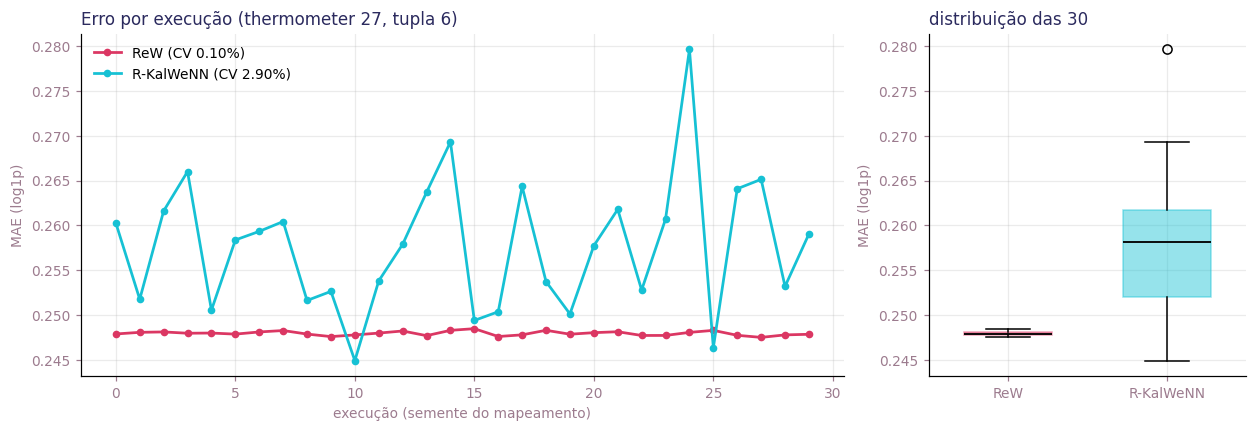

In [21]:
SEEDS_6 = range(30)

melhor = tab5.loc[tab5.groupby("modelo").MAE.idxmin()].set_index("modelo")
MEDIA_REW_6 = melhor.loc["ReW", "media"]
MEDIA_KAL_6 = melhor.loc["R-KalWeNN", "media"]
print(f"média usada: ReW {MEDIA_REW_6}, R-KalWeNN {MEDIA_KAL_6}\n")

erros_rew, erros_kal, t0 = [], [], time.perf_counter()
for sd in SEEDS_6:
    mp = sorteia_mapping(Xb_tr.shape[1], TUPLA, seed=sd)
    rw = ReW(mp).fit(Xb_tr, y_train)
    erros_rew.append(metricas(y_test, [MEDIAS_REW[MEDIA_REW_6](l)
                                       for l in rw.pares(Xb_te)])[0])
    kw = RKalWeNN(mp, seed=sd, **PADRAO).fit(Xb_tr, y_train)
    erros_kal.append(metricas(y_test, [MEDIAS_KAL[MEDIA_KAL_6](l)
                                       for l in kw.pares(Xb_te)])[0])
    if (sd + 1) % 5 == 0:
        el = time.perf_counter() - t0
        print(f"  {sd+1:>2}/30   {el/60:.1f} min, faltam ~{el/(sd+1)*(30-sd-1)/60:.1f} min")

erros_rew, erros_kal = np.array(erros_rew), np.array(erros_kal)
cv = lambda v: 100 * v.std(ddof=1) / v.mean()
tab6 = pd.DataFrame({
    "modelo": ["ReW", "R-KalWeNN"], "media": [MEDIA_REW_6, MEDIA_KAL_6],
    "MAE_medio": [erros_rew.mean(), erros_kal.mean()],
    "desvio": [erros_rew.std(ddof=1), erros_kal.std(ddof=1)],
    "CV_%": [cv(erros_rew), cv(erros_kal)],
    "MAE_min": [erros_rew.min(), erros_kal.min()],
    "MAE_max": [erros_rew.max(), erros_kal.max()]})
print("\n" + tab6.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4), facecolor="white",
                       gridspec_kw={"width_ratios": [2.4, 1]})
s = np.arange(len(erros_rew))
ax[0].plot(s, erros_rew, "-o", ms=4, lw=1.8, color=C_REW, label=f"ReW (CV {cv(erros_rew):.2f}%)")
ax[0].plot(s, erros_kal, "-o", ms=4, lw=1.8, color=C_KAL, label=f"R-KalWeNN (CV {cv(erros_kal):.2f}%)")
ax[0].set(xlabel="execução (semente do mapeamento)", ylabel="MAE (log1p)")
ax[0].set_title(f"Erro por execução (thermometer {THERM}, tupla {TUPLA})",
                color=C_TIT, fontsize=11, loc="left")
ax[0].legend(frameon=False, fontsize=9)
bp = ax[1].boxplot([erros_rew, erros_kal], widths=.55, patch_artist=True,
                   medianprops=dict(color="black", lw=1.2))
for caixa, cor in zip(bp["boxes"], [C_REW, C_KAL]):
    caixa.set(facecolor=cor, alpha=.45, edgecolor=cor)
ax[1].set_xticklabels(["ReW", "R-KalWeNN"]); ax[1].set_ylabel("MAE (log1p)")
ax[1].set_title("distribuição das 30", color=C_TIT, fontsize=11, loc="left")
for e in ax:
    e.tick_params(colors=C_EIXO, labelsize=9)
    e.xaxis.label.set_color(C_EIXO); e.yaxis.label.set_color(C_EIXO)
plt.tight_layout(); plt.show()

---
## 7. Termômetro contra tupla

Varredura nos dois eixos, medindo três coisas por configuração: o erro dos dois
modelos, quantas vezes cada endereço é visitado, e quantos endereços foram vistos
uma única vez.

O erro sozinho empurra a tupla para cima, porque endereço maior separa mais os
exemplos. A estrutura de acesso puxa para baixo, porque com a tupla grande cada
endereço é visto uma vez só, o modelo vira consulta e a memória cresce.

**O limiar.** O ponto de operação é o de menor erro entre as configurações que
ainda têm revisita de verdade. Usamos dois critérios ao mesmo tempo, e os dois
precisam valer: mediana de visitas por endereço de pelo menos `LIM_MEDIANA`, e
no máximo `LIM_UMA` por cento dos endereços vistos uma única vez. A tabela
impressa mostra o que cada tupla entrega, para o limiar poder ser escolhido com
o dado na frente.

O termômetro varre de 3 em 3 para a varredura caber no tempo, já que este
notebook roda o modelo sem atalho.

In [22]:
SW_THERM = list(range(6, 31, 3))
SW_TUPLA = [2, 4, 6, 9, 12, 27, 36, 54]
SW_SEEDS = (0, 1)
MEDIA_REW_7, MEDIA_KAL_7 = MEDIA_REW_6, MEDIA_KAL_6

LIM_MEDIANA = 6.0     # mediana de visitas por endereço, no mínimo
LIM_UMA     = 25.0    # porcentagem de endereços vistos uma única vez, no máximo

linhas7, t0 = [], time.perf_counter()
for t in SW_THERM:
    Xb_t, Xb_s = termometro(X_train, t, mins, maxs), termometro(X_test, t, mins, maxs)
    for a in SW_TUPLA:
        if Xb_t.shape[1] // a < 2:
            continue
        mae_r, mae_k, vis, uma = [], [], None, None
        for sd in SW_SEEDS:
            mp = sorteia_mapping(Xb_t.shape[1], a, seed=sd)
            hp, dg = hiperparametros_padrao(Xb_t, y_train, mp)
            rw = ReW(mp).fit(Xb_t, y_train)
            mae_r.append(metricas(y_test, [MEDIAS_REW[MEDIA_REW_7](l)
                                           for l in rw.pares(Xb_s)])[0])
            kw = RKalWeNN(mp, seed=sd, **hp).fit(Xb_t, y_train)
            mae_k.append(metricas(y_test, [MEDIAS_KAL[MEDIA_KAL_7](l)
                                           for l in kw.pares(Xb_s)])[0])
            if vis is None:
                n = dg["visitas"]
                vis, uma = dg["mediana"], 100.0 * float((n == 1).mean())
                rams, ocup = mp.shape[0], len(n)
        linhas7.append(dict(therm=t, tupla=a, n_rams=rams, enderecos=ocup,
                            visitas_mediana=vis, pct_uma=uma,
                            MAE_rew=float(np.mean(mae_r)),
                            MAE_kal=float(np.mean(mae_k)),
                            MAE_kal_dp=float(np.std(mae_k))))
    print(f"  thermometer {t:>2} ... {time.perf_counter()-t0:5.0f}s")

sup = pd.DataFrame(linhas7)
sup.to_csv("varredura_08.csv", index=False)

por_tupla = sup.groupby("tupla").agg(
    visitas=("visitas_mediana", "median"), uma_pct=("pct_uma", "median"),
    rams=("n_rams", "median"), MAE_rew=("MAE_rew", "min"), MAE_kal=("MAE_kal", "min"))
print("\n" + por_tupla.to_string(float_format=lambda v: f"{v:.3f}"))

elegiveis = sup[(sup.visitas_mediana >= LIM_MEDIANA) & (sup.pct_uma <= LIM_UMA)]
print(f"\nlimiar: mediana >= {LIM_MEDIANA:g} visitas e no máximo {LIM_UMA:g}% vistos uma vez")
print(f"configurações elegíveis: {len(elegiveis)} de {len(sup)}")
if len(elegiveis):
    esc = elegiveis.loc[elegiveis.MAE_kal.idxmin()]
    T_OK, A_OK = int(esc.therm), int(esc.tupla)
    print(f"escolha: thermometer {T_OK}, tupla {A_OK}, "
          f"MAE {esc.MAE_kal:.4f}, {int(esc.n_rams)} RAM nodes, "
          f"mediana de {esc.visitas_mediana:.0f} visitas, {esc.pct_uma:.0f}% vistos uma vez")
else:
    T_OK, A_OK = THERM, TUPLA
    print("nenhuma configuração passa no limiar; mantendo o ponto da Seção 5")

  thermometer  6 ...    38s
  thermometer  9 ...    96s
  thermometer 12 ...   169s
  thermometer 15 ...   268s
  thermometer 18 ...   385s
  thermometer 21 ...   513s
  thermometer 24 ...   683s
  thermometer 27 ...   877s
  thermometer 30 ...  1096s

       visitas  uma_pct     rams  MAE_rew  MAE_kal
tupla                                             
2       57.000    8.148 2988.000    0.289    0.295
4       14.000   16.289 1494.000    0.266    0.273
6        6.000   23.283  996.000    0.248    0.255
9        3.000   31.601  664.000    0.224    0.234
12       2.000   38.927  498.000    0.207    0.217
27       1.000   63.119  221.000    0.161    0.168
36       1.000   72.578  166.000    0.148    0.153
54       1.000   84.792  110.000    0.134    0.138

limiar: mediana >= 6 visitas e no máximo 25% vistos uma vez
configurações elegíveis: 27 de 72
escolha: thermometer 9, tupla 6, MAE 0.2553, 498 RAM nodes, mediana de 6 visitas, 23% vistos uma vez


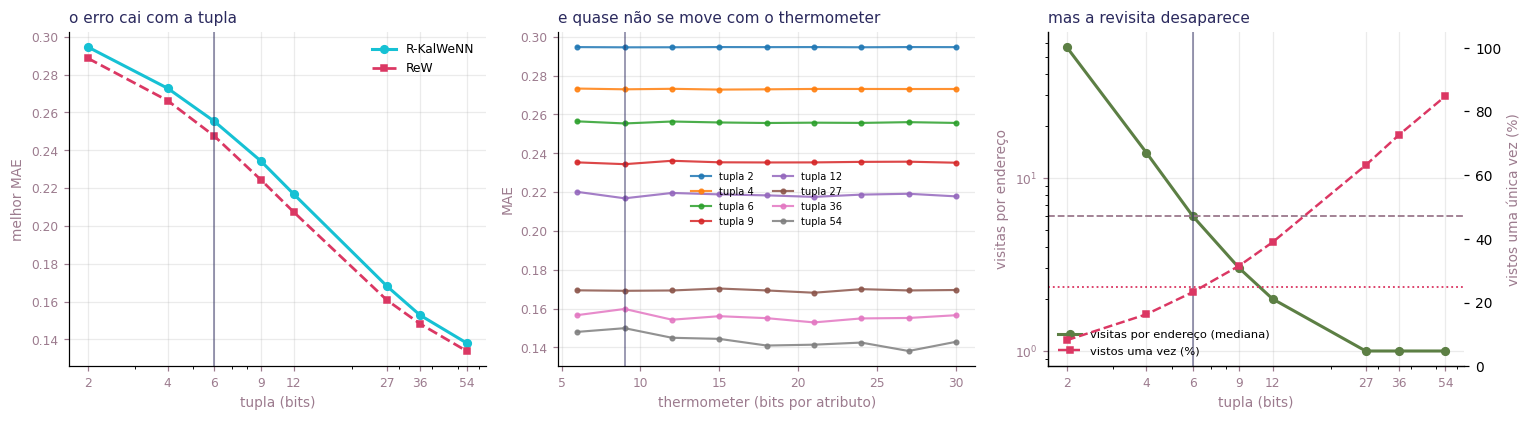

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9), facecolor="white")

ax[0].plot(por_tupla.index, por_tupla.MAE_kal, "o-", lw=2, ms=5, color=C_KAL,
           label="R-KalWeNN")
ax[0].plot(por_tupla.index, por_tupla.MAE_rew, "s--", lw=1.8, ms=4, color=C_REW,
           label="ReW")
ax[0].set(xlabel="tupla (bits)", ylabel="melhor MAE", xscale="log")
ax[0].set_xticks(SW_TUPLA); ax[0].set_xticklabels(SW_TUPLA)
ax[0].set_title("o erro cai com a tupla", color=C_TIT, fontsize=10, loc="left")
ax[0].legend(frameon=False, fontsize=8)

for a_, g in sup.groupby("tupla"):
    g = g.sort_values("therm")
    ax[1].plot(g.therm, g.MAE_kal, "-o", ms=3, lw=1.4, alpha=.85, label=f"tupla {a_}")
ax[1].set(xlabel="thermometer (bits por atributo)", ylabel="MAE")
ax[1].set_title("e quase não se move com o thermometer", color=C_TIT, fontsize=10, loc="left")
ax[1].legend(frameon=False, fontsize=6.5, ncol=2)

ax[2].plot(por_tupla.index, por_tupla.visitas, "o-", lw=2, ms=5, color=C_TRES,
           label="visitas por endereço (mediana)")
ax[2].axhline(LIM_MEDIANA, color=C_EIXO, ls="--", lw=1.2)
ax[2].set(xlabel="tupla (bits)", ylabel="visitas por endereço",
          xscale="log", yscale="log")
ax[2].set_xticks(SW_TUPLA); ax[2].set_xticklabels(SW_TUPLA)
a2 = ax[2].twinx()
a2.plot(por_tupla.index, por_tupla.uma_pct, "s--", lw=1.6, ms=4, color=C_REW,
        label="vistos uma vez (%)")
a2.axhline(LIM_UMA, color=C_REW, ls=":", lw=1.2)
a2.set_ylabel("vistos uma única vez (%)", color=C_EIXO); a2.set_ylim(0, 105); a2.grid(False)
ax[2].set_title("mas a revisita desaparece", color=C_TIT, fontsize=10, loc="left")
h1, l1 = ax[2].get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
ax[2].legend(h1 + h2, l1 + l2, frameon=False, fontsize=7.5, loc="lower left")

for e in (ax[0], ax[2]):
    e.axvline(A_OK, color=C_TIT, lw=1.2, alpha=.5)
ax[1].axvline(T_OK, color=C_TIT, lw=1.2, alpha=.5)
for e in ax:
    e.tick_params(colors=C_EIXO, labelsize=8)
    e.xaxis.label.set_color(C_EIXO); e.yaxis.label.set_color(C_EIXO)
plt.tight_layout(); plt.show()

---
## 8. Os seis hiperparâmetros

No ponto de operação escolhido na Seção 7, varremos um hiperparâmetro por vez
sobre a grade dele, com os outros cinco parados no valor padrão daquele ponto.

Nenhum `q` é zero: sem ruído de processo a recursão deixa de depender da ordem
de apresentação e vira média encolhida, e aí não é mais um filtro.

ponto de operação: thermometer 9, tupla 6
  p0_c  = 1
  r_c   = 6   >>> FORA DA GRADE <<<
  q_c   = 1.66667e-05   >>> FORA DA GRADE <<<
  p0_y  = 100
  r_y   = 1.36367
  x0_c  = 0
  x0_y  = 12.0215
  q_y   = 0.0378798   >>> FORA DA GRADE <<<
  p0_c  ...    33s
  q_c   ...    71s
  r_c   ...   103s
  p0_y  ...   138s
  q_y   ...   162s
  r_y   ...   210s


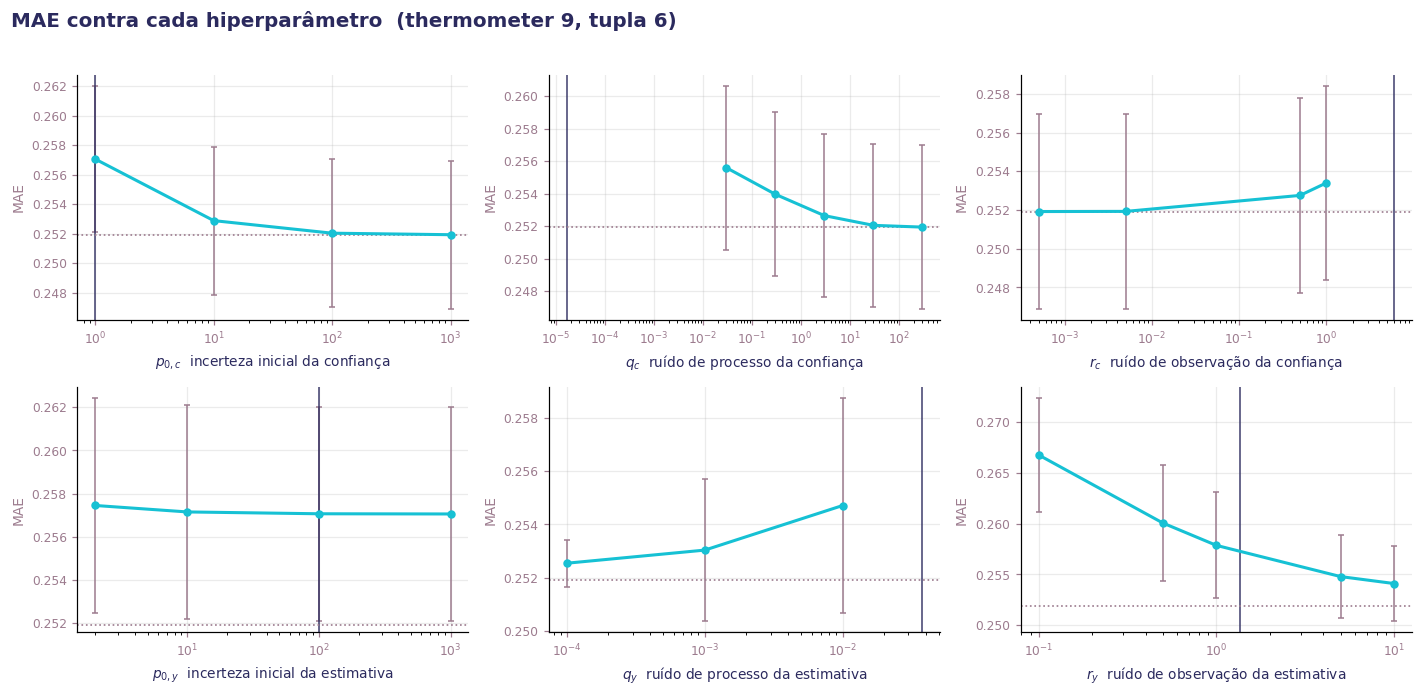


melhor nível de cada hiperparâmetro

  p0_c  padrão           1   melhor        1000   MAE 0.2519   MAIOR nível
  q_c   padrão  1.6667e-05   melhor         300   MAE 0.2519   MAIOR nível
  r_c   padrão           6   melhor      0.0005   MAE 0.2519   MENOR nível
  p0_y  padrão         100   melhor        1000   MAE 0.2571   MAIOR nível
  q_y   padrão     0.03788   melhor      0.0001   MAE 0.2525   MENOR nível
  r_y   padrão      1.3637   melhor          10   MAE 0.2541   MAIOR nível


In [26]:
SEEDS_8 = (0, 1, 2)

GRADES = {
    "p0_c": [1.0, 10.0, 100.0, 1000],
    "q_c":  [0.03, 0.3, 3.0, 30.0, 300.0],
    "r_c":  [0.0005, 0.005, 0.5, 1.0],
    "p0_y": [2.0, 10.0, 100.0, 1000.0],
    "q_y":  [0.0001, 0.001, 0.01],
    "r_y":  [0.1, 0.5, 1.0, 5.0, 10.0],
}
ROTULO = {"p0_c": "$p_{0,c}$  incerteza inicial da confiança",
          "q_c": "$q_c$  ruído de processo da confiança",
          "r_c": "$r_c$  ruído de observação da confiança",
          "p0_y": "$p_{0,y}$  incerteza inicial da estimativa",
          "q_y": "$q_y$  ruído de processo da estimativa",
          "r_y": "$r_y$  ruído de observação da estimativa"}

Xb_t8 = termometro(X_train, T_OK, mins, maxs)
Xb_s8 = termometro(X_test,  T_OK, mins, maxs)
map_8 = sorteia_mapping(Xb_t8.shape[1], A_OK, seed=0)
PADRAO_8, _ = hiperparametros_padrao(Xb_t8, y_train, map_8)
print(f"ponto de operação: thermometer {T_OK}, tupla {A_OK}")
for k, v in PADRAO_8.items():
    dentro = k not in GRADES or min(GRADES[k]) <= v <= max(GRADES[k])
    marca = "" if dentro else "   >>> FORA DA GRADE <<<"
    print(f"  {k:5s} = {v:.6g}{marca}")

linhas8, t0 = [], time.perf_counter()
for par, grade in GRADES.items():
    for v in grade:
        hp = dict(PADRAO_8); hp[par] = v
        maes = []
        for sd in SEEDS_8:
            kw = RKalWeNN(map_8, seed=sd, **hp).fit(Xb_t8, y_train)
            maes.append(metricas(y_test, [MEDIAS_KAL[MEDIA_KAL_7](l)
                                          for l in kw.pares(Xb_s8)])[0])
        linhas8.append(dict(parametro=par, valor=v,
                            MAE=float(np.mean(maes)), MAE_dp=float(np.std(maes))))
    print(f"  {par:5s} ... {time.perf_counter()-t0:5.0f}s")
sens = pd.DataFrame(linhas8)
sens.to_csv("sensibilidade_08.csv", index=False)

piso = float(sens.MAE.min())
fig, ax = plt.subplots(2, 3, figsize=(13, 6.4), facecolor="white")
for a_, par in zip(ax.ravel(), GRADES):
    g = sens[sens.parametro == par].sort_values("valor")
    a_.errorbar(g.valor, g.MAE, yerr=g.MAE_dp, fmt="o-", lw=2, ms=4.5,
                color=C_KAL, ecolor=C_EIXO, elinewidth=1, capsize=2)
    a_.axvline(PADRAO_8[par], color=C_TIT, lw=1.3, alpha=.7)
    a_.axhline(piso, color=C_EIXO, ls=":", lw=1.1)
    a_.set(xscale="log", xlabel=ROTULO[par], ylabel="MAE")
    a_.tick_params(colors=C_EIXO, labelsize=8)
    a_.xaxis.label.set_color(C_TIT); a_.yaxis.label.set_color(C_EIXO)
fig.suptitle(f"MAE contra cada hiperparâmetro  (thermometer {T_OK}, tupla {A_OK})",
             fontsize=13, fontweight="bold", color=C_TIT, x=0.01, ha="left")
plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

print("\nmelhor nível de cada hiperparâmetro\n")
for par, grade in GRADES.items():
    g = sens[sens.parametro == par]
    b = g.loc[g.MAE.idxmin()]
    borda = ("MENOR nível" if b.valor == min(grade)
             else "MAIOR nível" if b.valor == max(grade) else "interior")
    print(f"  {par:5s} padrão {PADRAO_8[par]:>11.5g}   melhor {b.valor:>11.5g}"
          f"   MAE {b.MAE:.4f}   {borda}")

---
## 9. Tabela final

Três linhas. A ReW e o R-KalWeNN no ponto de operação escolhido na Seção 7, cada
um **no melhor ajuste dele**, e a ReW publicada na tese como referência.

Melhor ajuste quer dizer coisas diferentes para cada modelo, e o texto do artigo
precisa dizer isso. A ReW tem um grau de liberdade, a função de agregação, e
entra com a melhor das seis. O R-KalWeNN tem a função de agregação e mais os
mecanismos do filtro, então ele entra com a melhor combinação de uma busca
pequena sobre esses mecanismos.

A busca do R-KalWeNN cobre as três coisas que a Seção 8 mostrou importarem, cada
uma em dois ou três níveis:

- **ponderação**: confiança ancorada na mediana de visitas, ou confiança
  uniforme, que é o mesmo que desligar a ponderação;
- **esquecimento**: ruído de processo ancorado, ou praticamente nulo;
- **encolhimento**: nenhum, fraco ou moderado.

Os dois modelos são escolhidos olhando o erro de teste, o que também é o que o
código da tese faz. É uma limitação, e ela vale para as duas linhas por igual, de
modo que a comparação entre elas continua simétrica.

A tese não publica os hiperparâmetros vencedores do House Prices, então a linha
dela traz só o MAE, na mesma escala log1p, e sem desvio.

In [27]:
SEEDS_9 = (0, 1, 2)

Xb_t9 = termometro(X_train, T_OK, mins, maxs)
Xb_s9 = termometro(X_test,  T_OK, mins, maxs)
map_ref = sorteia_mapping(Xb_t9.shape[1], A_OK, seed=0)
ANC, _ = hiperparametros_padrao(Xb_t9, y_train, map_ref)   # valores ancorados
print(f"ponto de operação: thermometer {T_OK}, tupla {A_OK}")
print(f"ancorados: r_c={ANC['r_c']:.4g}, q_c={ANC['q_c']:.4g}, "
      f"r_y={ANC['r_y']:.4g}, q_y={ANC['q_y']:.4g}\n")

PONDERACAO = {"ancorada": dict(p0_c=1.0, r_c=ANC["r_c"], q_c=ANC["q_c"]),
              "uniforme": dict(p0_c=1.0, r_c=1e-6,      q_c=0.0)}
ESQUECIMENTO = {"ancorado": ANC["q_y"], "nenhum": 0.0}
ENCOLHIMENTO = {"nenhum": 1e-6, "fraco": 0.05, "moderado": 0.2}   # a = r_y / p0_y

# ── ReW: a memória não depende da média, treina uma vez por execução ─────────
acum_rew, t0 = {}, time.perf_counter()
for sd in SEEDS_9:
    mp = sorteia_mapping(Xb_t9.shape[1], A_OK, seed=sd)
    rw = ReW(mp).fit(Xb_t9, y_train)
    pr = rw.pares(Xb_s9)
    for nome, f in MEDIAS_REW.items():
        acum_rew.setdefault(nome, []).append(metricas(y_test, [f(l) for l in pr]))
print(f"  ReW pronta ... {time.perf_counter()-t0:.0f}s")

# ── R-KalWeNN: busca pequena sobre os três mecanismos ────────────────────────
acum_kal = {}
for pond, hp_c in PONDERACAO.items():
    for esq, q_y in ESQUECIMENTO.items():
        for enc, a in ENCOLHIMENTO.items():
            for sd in SEEDS_9:
                mp = sorteia_mapping(Xb_t9.shape[1], A_OK, seed=sd)
                hp = dict(hp_c, p0_y=1.0, r_y=a, q_y=q_y,
                          x0_c=0.0, x0_y=float(np.mean(y_train)))
                kw = RKalWeNN(mp, seed=sd, **hp).fit(Xb_t9, y_train)
                pk = kw.pares(Xb_s9)
                for nome, f in MEDIAS_KAL.items():
                    acum_kal.setdefault((pond, esq, enc, nome), []).append(
                        metricas(y_test, [f(l) for l in pk]))
    print(f"  R-KalWeNN ponderação {pond} ... {time.perf_counter()-t0:.0f}s")

def resume(chave, vals):
    v = np.array([[a, b, c] for a, b, c, _, _ in vals])
    return dict(MAE=v[:, 0].mean(), MAE_dp=v[:, 0].std(ddof=1),
                RMSE=v[:, 1].mean(), R2=v[:, 2].mean())

busca_rew = pd.DataFrame([dict(media=k, **resume(k, v)) for k, v in acum_rew.items()])
busca_kal = pd.DataFrame([dict(ponderacao=k[0], esquecimento=k[1], encolhimento=k[2],
                               media=k[3], **resume(k, v))
                          for k, v in acum_kal.items()])
busca_kal.to_csv("busca_final_08.csv", index=False)

print("\nReW, por média\n")
print(busca_rew.sort_values("MAE").to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nR-KalWeNN, as 10 melhores combinações\n")
print(busca_kal.nsmallest(10, "MAE").to_string(index=False, float_format=lambda v: f"{v:.4f}"))

b_rew = busca_rew.loc[busca_rew.MAE.idxmin()]
b_kal = busca_kal.loc[busca_kal.MAE.idxmin()]

tab9 = pd.DataFrame([
    {"modelo": "R-KalWeNN", "ajuste": f"{b_kal.media}, ponderação {b_kal.ponderacao}, "
                                      f"esquecimento {b_kal.esquecimento}, "
                                      f"encolhimento {b_kal.encolhimento}",
     "thermometer": T_OK, "tupla": A_OK,
     "MAE": f"{b_kal.MAE:.4f} ± {b_kal.MAE_dp:.4f}",
     "RMSE": f"{b_kal.RMSE:.4f}", "R2": f"{b_kal.R2:.4f}"},
    {"modelo": "ReW", "ajuste": f"{b_rew.media}",
     "thermometer": T_OK, "tupla": A_OK,
     "MAE": f"{b_rew.MAE:.4f} ± {b_rew.MAE_dp:.4f}",
     "RMSE": f"{b_rew.RMSE:.4f}", "R2": f"{b_rew.R2:.4f}"},
    {"modelo": "ReW (tese)", "ajuste": "não publicado",
     "thermometer": "não publicado", "tupla": "não publicado",
     "MAE": f"{REF_TESE:.3f}", "RMSE": "—", "R2": "—"},
])
tab9.to_csv("tabela_final_08.csv", index=False)
print("\n\nTABELA FINAL\n")
print(tab9.to_string(index=False))
print(f"\nR-KalWeNN contra a nossa ReW  : {b_kal.MAE - b_rew.MAE:+.4f}")
print(f"R-KalWeNN contra a ReW da tese: {b_kal.MAE - REF_TESE:+.4f}")
print(f"chutar a média do treino      : {mae_media:.4f}")

todas as médias no ponto escolhido (thermometer 9, tupla 6), 5 execuções

   modelo            media    MAE  MAE_dp   RMSE     R2
R-KalWeNN K-Harmonic power 0.2573  0.0070 0.3414 0.2937
R-KalWeNN       K-Harmonic 0.2574  0.0070 0.3414 0.2936
R-KalWeNN         K-Simple 0.2577  0.0071 0.3414 0.2934
R-KalWeNN          K-Power 0.2578  0.0071 0.3415 0.2933
R-KalWeNN    K-Exponential 0.2587  0.0077 0.3413 0.2941
R-KalWeNN         K-Median 0.2791  0.0094 0.3653 0.1908
      ReW      Exponential 0.2474  0.0004 0.3290 0.3443
      ReW   Harmonic power 0.2475  0.0004 0.3307 0.3373
      ReW         Harmonic 0.2476  0.0004 0.3307 0.3376
      ReW            Power 0.2476  0.0004 0.3304 0.3385
      ReW           Median 0.2714  0.0018 0.3567 0.2290
      ReW           Simple 0.2860  0.0009 0.3758 0.1441


TABELA FINAL

    modelo            média   thermometer         tupla             MAE   RMSE     R2
 R-KalWeNN K-Harmonic power             9             6 0.2573 ± 0.0070 0.3414 0.2937
       ReW